In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import json
import re
import uproot
from pathlib import Path
import pandas as pd

from torch.utils.data import random_split
# from glasflow.nflows import distributions, flows

# from v1_1_pmssm_model.load_data import *
# from v1_1_pmssm_model.norm_flow import *

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


##### How to get root files from subdirectories in a fast way

In [2]:
import time

start = time.perf_counter()

# Code to measure
for root, dirs, files in os.walk("/ptmp/yinya/gen_flat_v2/"):
    pass

elapsed = time.perf_counter() - start
print(f"{elapsed:.6f} seconds")


start = time.perf_counter()

# Code to measure
for dirs in os.listdir("/ptmp/yinya/gen_flat_v2/"):
    pass

elapsed = time.perf_counter() - start
print(f"{elapsed:.6f} seconds")

73.228613 seconds
0.001636 seconds


In [3]:
start = time.perf_counter()

file_names = []
for root, dirs, files in os.walk("/ptmp/yinya/gen_flat_v2/", topdown=True):
    relative = os.path.relpath(root, "/ptmp/yinya/gen_flat_v2/")
    depth = 0 if relative == "." else relative.count(os.sep) + 1

    if depth >= 1:
        dirs[:] = []  # Don't descend to depth 2

    # This collects .root files at depth 0 and depth 1.
    for filename in files:
        if filename.endswith(".root"):
            file_names.append(os.path.join(root, filename))


elapsed = time.perf_counter() - start
print(f"{elapsed:.6f} seconds")

0.067744 seconds


In [4]:
import time

start = time.perf_counter()

root = Path("/ptmp/yinya/gen_flat_v2/")
file_names = []
file_names.extend(
    path
    for pattern in ("ntuple.*.*.root", "*/ntuple.*.*.root")
    for path in root.glob(pattern)
    if path.is_file()
)

elapsed = time.perf_counter() - start
print(f"{elapsed:.6f} seconds")

0.077086 seconds


In [17]:
print(file_names)

[PosixPath('/ptmp/yinya/gen_flat_v2/scan.261012162356.87/ntuple.261012162356.87.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.221/ntuple.260930143546.221.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.33/ntuple.260930143546.33.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.3/ntuple.260930143546.3.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.261012162356.38/ntuple.261012162356.38.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.103/ntuple.260930143546.103.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.63/ntuple.260930143546.63.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.261012162356.0/ntuple.261012162356.0.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.203/ntuple.260930143546.203.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.102/ntuple.260930143546.102.root'), PosixPath('/ptmp/yinya/gen_flat_v2/scan.260930143546.174/ntuple.260930143546.174.root'), PosixPath('/ptmp/yinya/gen_flat_v2/s

##### Load Data

In [22]:
# TODO: 1.Adapt the load_data.py with new changes in _ntuple_index and _collect__files (from pathlib import Path)
#2. Make sure to save the list of used files for each training for reproducibility 
#3. Use --max_files and --fraction before reading
#4. Add --specify_files for reproducing

In [2]:

def _ntuple_index(filename):
    match = re.fullmatch(r'ntuple\.(\d+)\.(\d+)\.root', filename)
    if match:
        return int(match.group(1)), int(match.group(2))
    return float('inf'), float('inf')

def _collect_files(data_folders):
    """
    Collects all .root files from the data folders and their direct subfolders
    Sorts them based on the ntuple index extracted from their filenames
    - data_folders: a list of folder paths or a single folder path
    """
    if isinstance(data_folders, (str, os.PathLike)):
        data_folders = [data_folders]

    file_names = []
    for folder in data_folders:
        folder = Path(folder)
        file_names.extend(
            path
            for pattern in ("ntuple.*.*.root", "*/ntuple.*.*.root")
            for path in folder.glob(pattern)
            if path.is_file()
        )

    file_names.sort(
        key=lambda path: _ntuple_index(os.path.basename(path))
    )
    return file_names

def _split_constant_nonconstant_columns(df: pd.DataFrame, return_names = False):
    """
    Splits a DataFrame into:
    - constant_df: columns where all values are identical
    - nonconstant_df: columns where at least one value differs
    """

    # A column is constant if it has exactly one unique value
    constant_columns = df.nunique(dropna=False) == 1

    constant_df = df.loc[:, constant_columns]
    nonconstant_df = df.loc[:, ~constant_columns]

    if return_names:
        return constant_df.columns, nonconstant_df.columns
    else:
        return constant_df, nonconstant_df

In [8]:
# data_folder = '/ptmp/yinya/gen_flat_v2/'
data_folder = '/u/yinya/archive/gen_flat_v2/ntuples'

data_folders = [data_folder] if isinstance(data_folder, str) else data_folder
file_names = _collect_files(data_folders)

# Determine non-constant theory parameters from the first file
with uproot.open(file_names[0]) as file:
    key = file.keys()[0]
    tree = file[key]
    theory_param = [branch for branch in tree.keys() if branch.startswith('IN')]
    theory_tree = tree.arrays(theory_param, library='pd')
    _, theory_param_nonconst = _split_constant_nonconstant_columns(theory_tree, return_names=True)
    # print([branch for branch in tree.keys() if branch.startswith('SP')])

['SP_err_tachyon', 'SP_err_tachyon_sbottom', 'SP_err_tachyon_stop', 'SP_err_tachyon_snutau', 'SP_err_tachyon_A0', 'SP_err_tachyon_stau', 'SP_err_tachyon_hpm', 'SP_err_tachyon_m3sq_problem', 'SP_err_tachyon_other', 'SP_err_m3sq_problem', 'SP_err_stop_LSP', 'SP_err_higgs_potential', 'SP_err_num', 'SP_err_other', 'SP_LSP_type', 'SP_LSP_mass', 'SP_LSQ_type', 'SP_LSQ_mass', 'SP_tanb_min', 'SP_M_1', 'SP_M_2', 'SP_M_3', 'SP_At', 'SP_Ab', 'SP_Atau', 'SP_mu', 'SP_tanb_ext', 'SP_mA', 'SP_meL', 'SP_mmuL', 'SP_mtauL', 'SP_meR', 'SP_mmuR', 'SP_mtauR', 'SP_mqL1', 'SP_mqL2', 'SP_mqL3', 'SP_muR', 'SP_mcR', 'SP_mtR', 'SP_mdR', 'SP_msR', 'SP_mbR', 'SP_m_W', 'SP_m_h', 'SP_m_H', 'SP_m_A', 'SP_m_Hp', 'SP_m_d_L', 'SP_m_d_R', 'SP_m_u_L', 'SP_m_u_R', 'SP_m_s_L', 'SP_m_s_R', 'SP_m_c_L', 'SP_m_c_R', 'SP_m_b_1', 'SP_m_b_2', 'SP_m_t_1', 'SP_m_t_2', 'SP_m_e_L', 'SP_m_e_R', 'SP_m_nu_eL', 'SP_m_mu_L', 'SP_m_mu_R', 'SP_m_nu_muL', 'SP_m_tau_1', 'SP_m_tau_2', 'SP_m_nu_tauL', 'SP_m_gl', 'SP_m_chi_10', 'SP_m_chi_20', 'SP

In [9]:
with uproot.open(file_names[0]) as file:
    key = file.keys()[0]
    tree = file[key]
    for key in tree.keys():
        print(key)

model
Maywarning
IN_err_tachyon
IN_err_tachyon_sbottom
IN_err_tachyon_stop
IN_err_tachyon_snutau
IN_err_tachyon_A0
IN_err_tachyon_stau
IN_err_tachyon_hpm
IN_err_tachyon_m3sq_problem
IN_err_tachyon_other
IN_err_m3sq_problem
IN_err_stop_LSP
IN_err_higgs_potential
IN_err_num
IN_err_other
IN_M_1
IN_M_2
IN_M_3
IN_At
IN_Ab
IN_Atau
IN_mu
IN_tanb
IN_mA
IN_meL
IN_mmuL
IN_mtauL
IN_meR
IN_mmuR
IN_mtauR
IN_mqL1
IN_mqL2
IN_mqL3
IN_muR
IN_mcR
IN_mtR
IN_mdR
IN_msR
IN_mbR
SP_err_tachyon
SP_err_tachyon_sbottom
SP_err_tachyon_stop
SP_err_tachyon_snutau
SP_err_tachyon_A0
SP_err_tachyon_stau
SP_err_tachyon_hpm
SP_err_tachyon_m3sq_problem
SP_err_tachyon_other
SP_err_m3sq_problem
SP_err_stop_LSP
SP_err_higgs_potential
SP_err_num
SP_err_other
SS_err_tachyon
SS_err_tachyon_sbottom
SS_err_tachyon_stop
SS_err_tachyon_snutau
SS_err_tachyon_A0
SS_err_tachyon_stau
SS_err_tachyon_hpm
SS_err_tachyon_m3sq_problem
SS_err_tachyon_other
SS_err_m3sq_problem
SS_err_stop_LSP
SS_err_higgs_potential
SS_err_num
SS_err_other
S

##### v1.1 Data Inspection

In [ ]:
all_parameters = [] # all non const theory param 
all_mo_omega = []
all_sp_m_chi_10 = []
for i, file_name in enumerate(file_names):
    with uproot.open(file_name) as file:
        key = file.keys()[0]
        tree = file[key]
        chunk = tree.arrays(theory_param_nonconst, library='np')
        all_parameters.append({k: v.astype(np.float32) for k, v in chunk.items()})
        all_mo_omega.append(tree['MO_Omega'].array(library="np").astype(np.float32))
        all_sp_m_chi_10.append(tree['SP_m_chi_10'].array(library="np").astype(np.float32))
        print(f"Loading files: {i+1}/{len(file_names)}", end='\r', flush=True)
print()

Loading files: 250/250


In [8]:

parameters = np.concatenate([np.stack(list(chunk.values()), axis=1) for chunk in all_parameters])
mo_omega = np.concatenate(all_mo_omega)[:, None]
sp_m_chi_10 = np.concatenate(all_sp_m_chi_10)[:, None]
print(f"Loaded {len(file_names)} files from {data_folders}\nTotal samples: {len(parameters)}")

#We get rid of the samples where mo_omega is -1
mask = (mo_omega != -1).flatten()
parameters = parameters[mask]
mo_omega = mo_omega[mask]
sp_m_chi_10 = sp_m_chi_10[mask]
print(f"Samples after filter on relic density: {len(parameters)}")

Loaded 250 files from ['/ptmp/yinya/gen_flat_28346825/ntuples']
Total samples: 2000000
Samples after filter on relic density: 1565111


In [16]:
sp_m_chi_10[:,0].shape

(1565111,)

/tmp/ipykernel_1649/2575229747.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  h = ax.scatter(sp_m_chi_10[:,0], mo_omega[:,0], cmap='viridis', s=1)


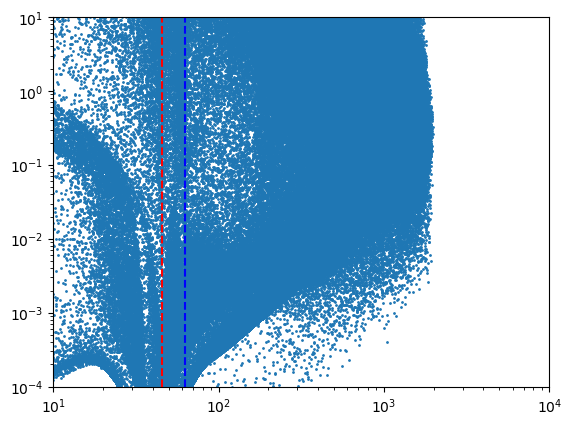

In [31]:
fig, ax = plt.subplots()
h = ax.scatter(sp_m_chi_10[:,0], mo_omega[:,0], cmap='viridis', s=1)

ax.set_xscale('log')
ax.set_yscale('log')

plt.axvline(91.19/2, color='red', linestyle='--', label=r'$m_Z$')
plt.axvline(125.25/2, color='blue', linestyle='--', label=r'$m_h$')


plt.xlim(1e1, 1e4)
plt.ylim(1e-4, 1e1)
plt.show()

##### v2 Data Distribution

In [5]:
[key for key in tree.keys() if 'SP_m_h' in key]

['SP_m_h']

In [10]:
nineteen_theory_params = ['IN_M_1', 'IN_M_2', 'IN_M_3', 'IN_At', 'IN_Ab', 'IN_Atau', 'IN_mu', 'IN_tanb', 'IN_mA', 'IN_meL', 'IN_mtauL', 'IN_meR', 'IN_mtauR', 'IN_mqL1', 'IN_mqL3', 'IN_muR', 'IN_mtR', 'IN_mdR', 'IN_mbR']
interesting_params = ['SModelS_bestExpUL_r_expected', 'SP_m_chi_10', 'SP_m_h', 'MO_Omega']
all_param_names = nineteen_theory_params + interesting_params

In [11]:
all_parameters = []
for i, file_name in enumerate(file_names):
    with uproot.open(file_name) as file:
        key = file.keys()[0]
        tree = file[key]
        chunk = tree.arrays(all_param_names, library='np')
        all_parameters.append({k: v.astype(np.float32) for k, v in chunk.items()})
        print(f"Loading files: {i+1}/{len(file_names)}", end='\r', flush=True)
print()
all_parameters = np.concatenate([np.stack(list(chunk.values()), axis=1) for chunk in all_parameters])
parameters = {
    name: all_parameters[:, i]
    for i, name in enumerate(all_param_names)
}

Loading files: 499/499


In [9]:
all_parameters.shape

(3648000, 23)

In [15]:
print(f"Loaded {len(file_names)} files from {data_folders}\nTotal samples: {len(all_parameters)}")

print(len(parameters['IN_M_1']))
#We get rid of the samples where mo_omega is -1
mask = (parameters['MO_Omega'] != -1).flatten()
all_parameters = all_parameters[mask]
parameters = {
    name: all_parameters[:, i]
    for i, name in enumerate(all_param_names)
}
print(len(parameters['IN_M_1']))
print(f"Samples after filter on relic density: {len(all_parameters)}")

Loaded 499 files from ['/u/yinya/archive/gen_flat_v2/ntuples']
Total samples: 3992000
3992000
3179439
Samples after filter on relic density: 3179439


In [23]:
len([i for i in parameters['SModelS_bestExpUL_r_expected'] if i == -1])

284808

/tmp/ipykernel_111705/2232935479.py:1: RuntimeWarning: invalid value encountered in log
  plt.hist(np.log(parameters['SModelS_bestExpUL_r_expected']))


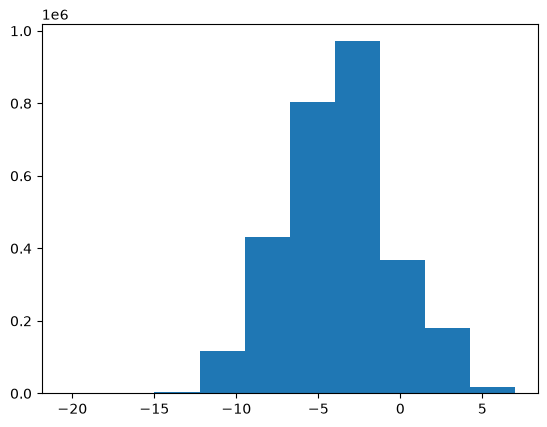

In [22]:
plt.hist(np.log(parameters['SModelS_bestExpUL_r_expected']))
plt.show()

In [17]:
all_non_const_param_names = list(theory_param_nonconst) + interesting_params
parameters_non_const = np.array([parameters[name] for i, name in enumerate(all_non_const_param_names)])

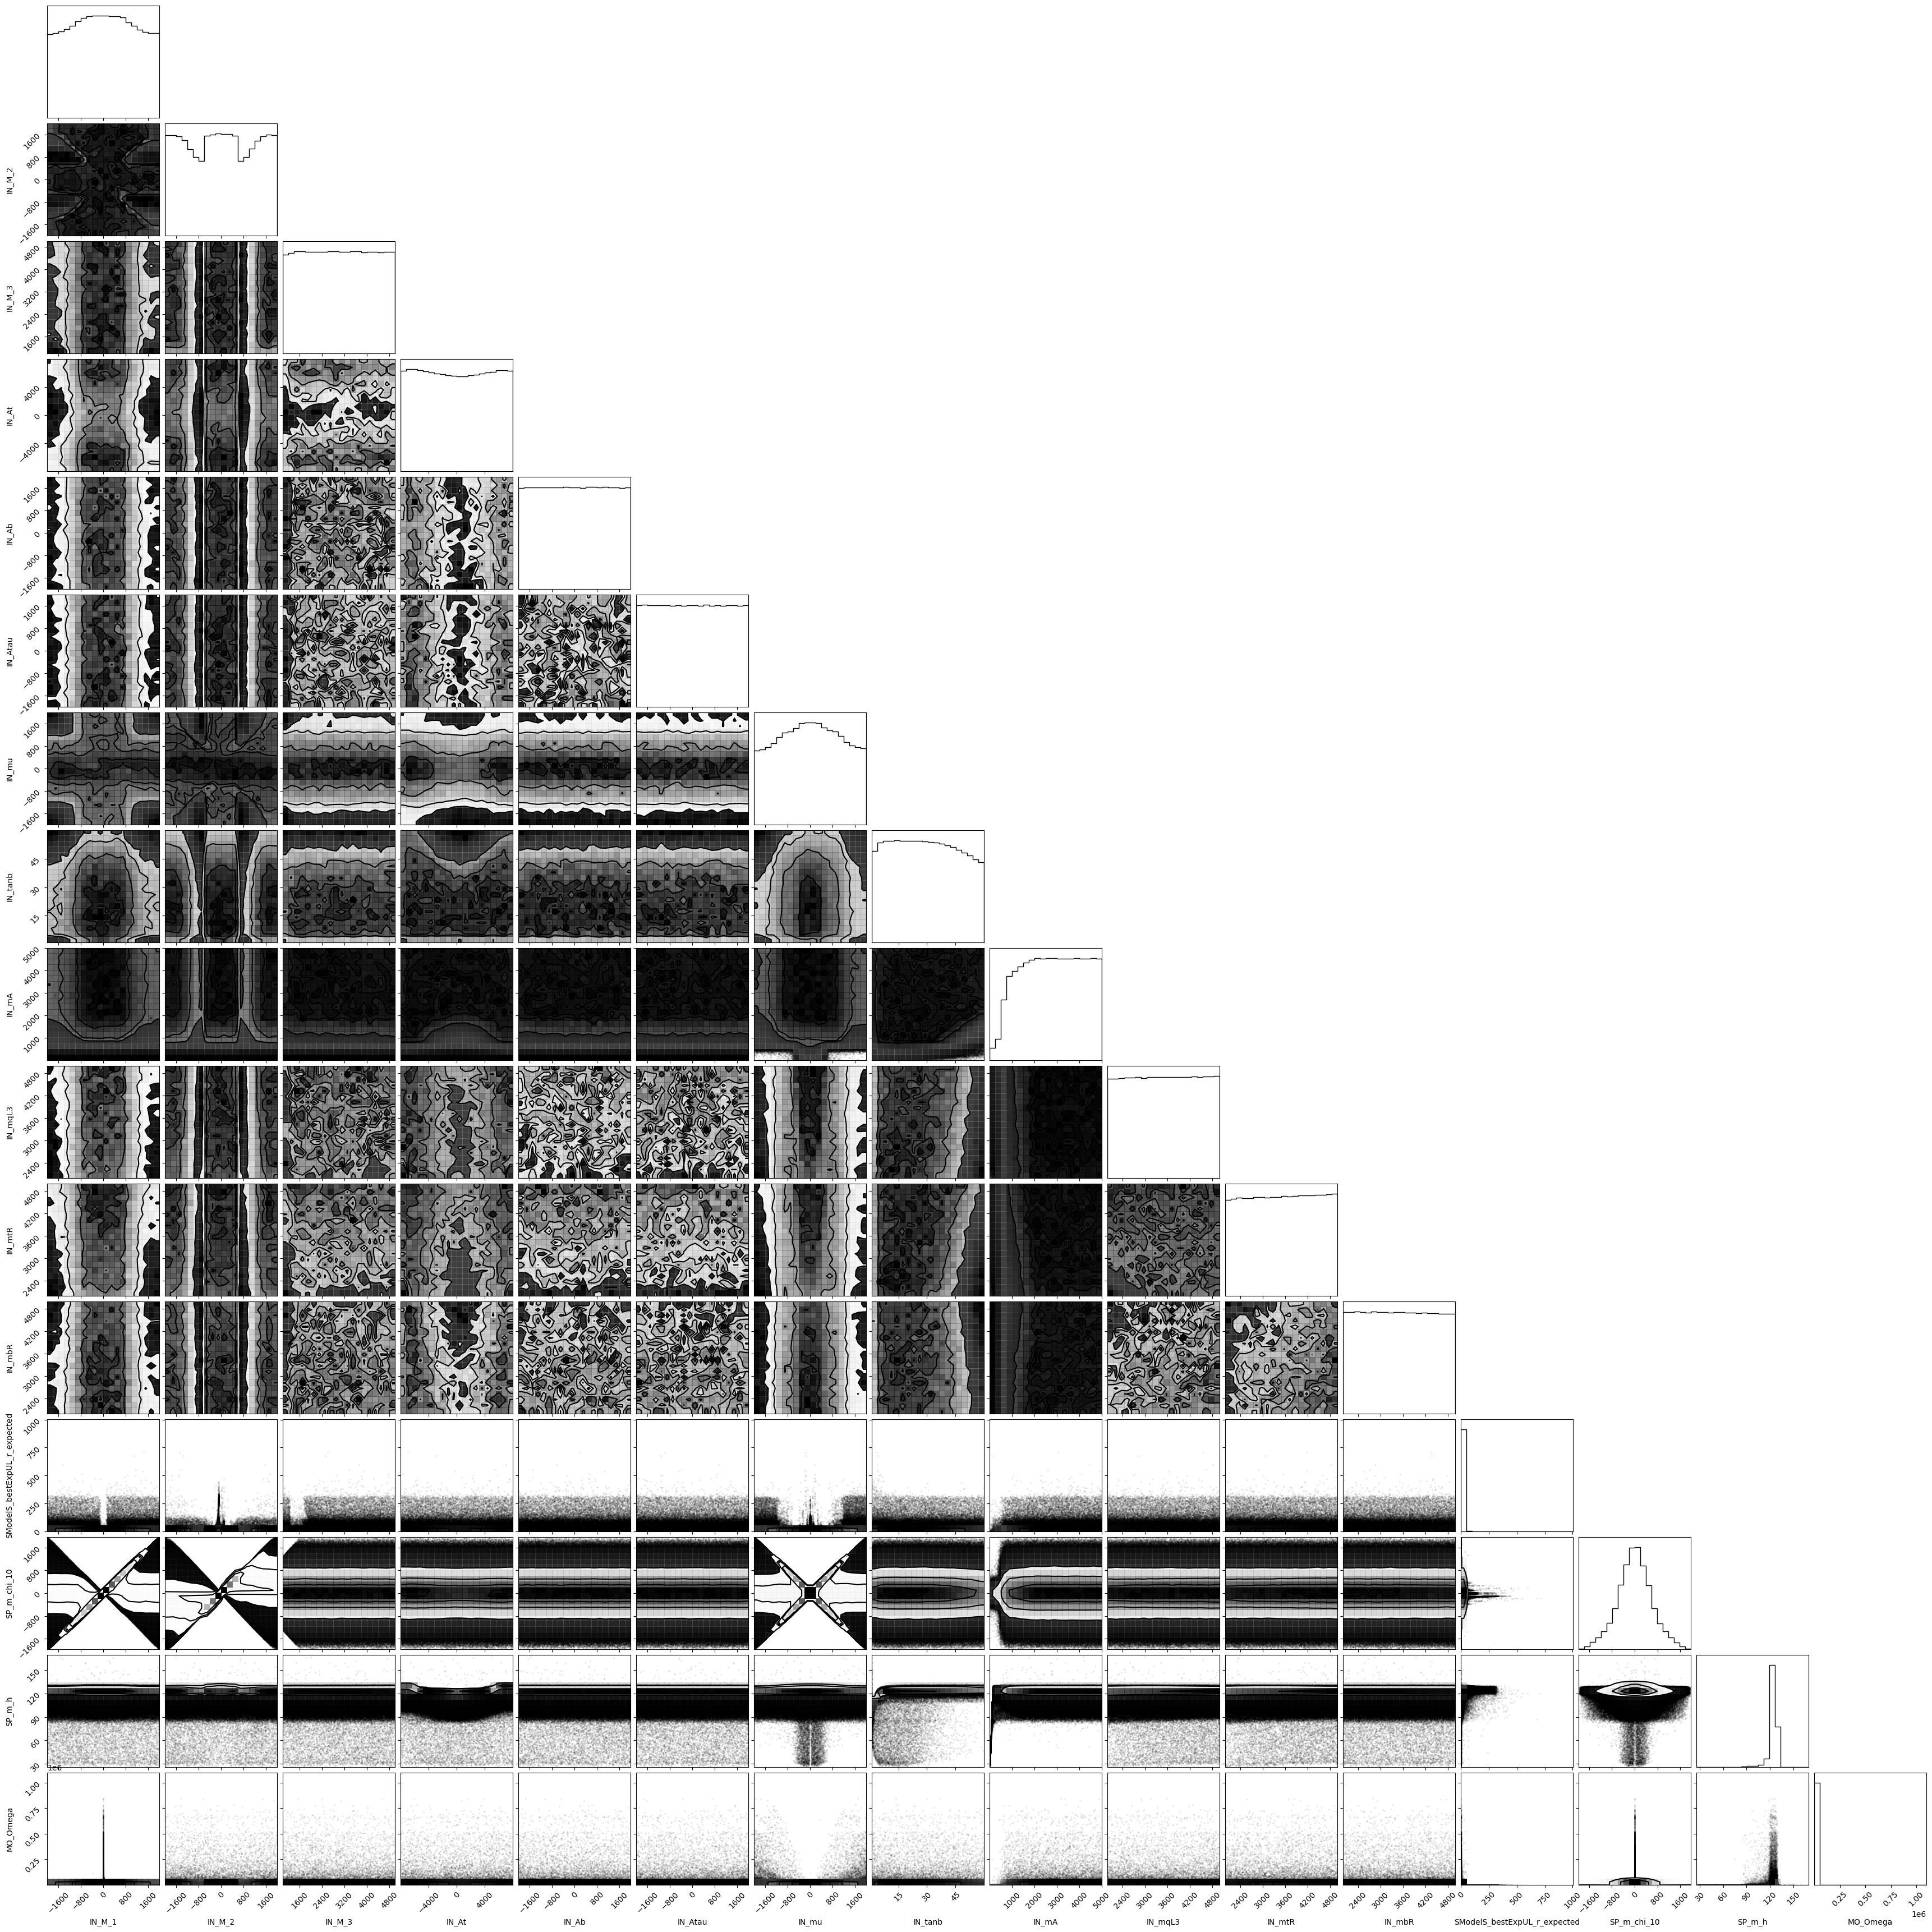

In [12]:
# Show only 1/10 of total samples to save time
# corner.corner(parameters_non_const[:, ::10].T, labels=all_non_const_param_names)
corner.corner(parameters_non_const.T, labels=all_non_const_param_names)
# corner.corner(parameters, labels=theory_param_nonconst)
plt.show()

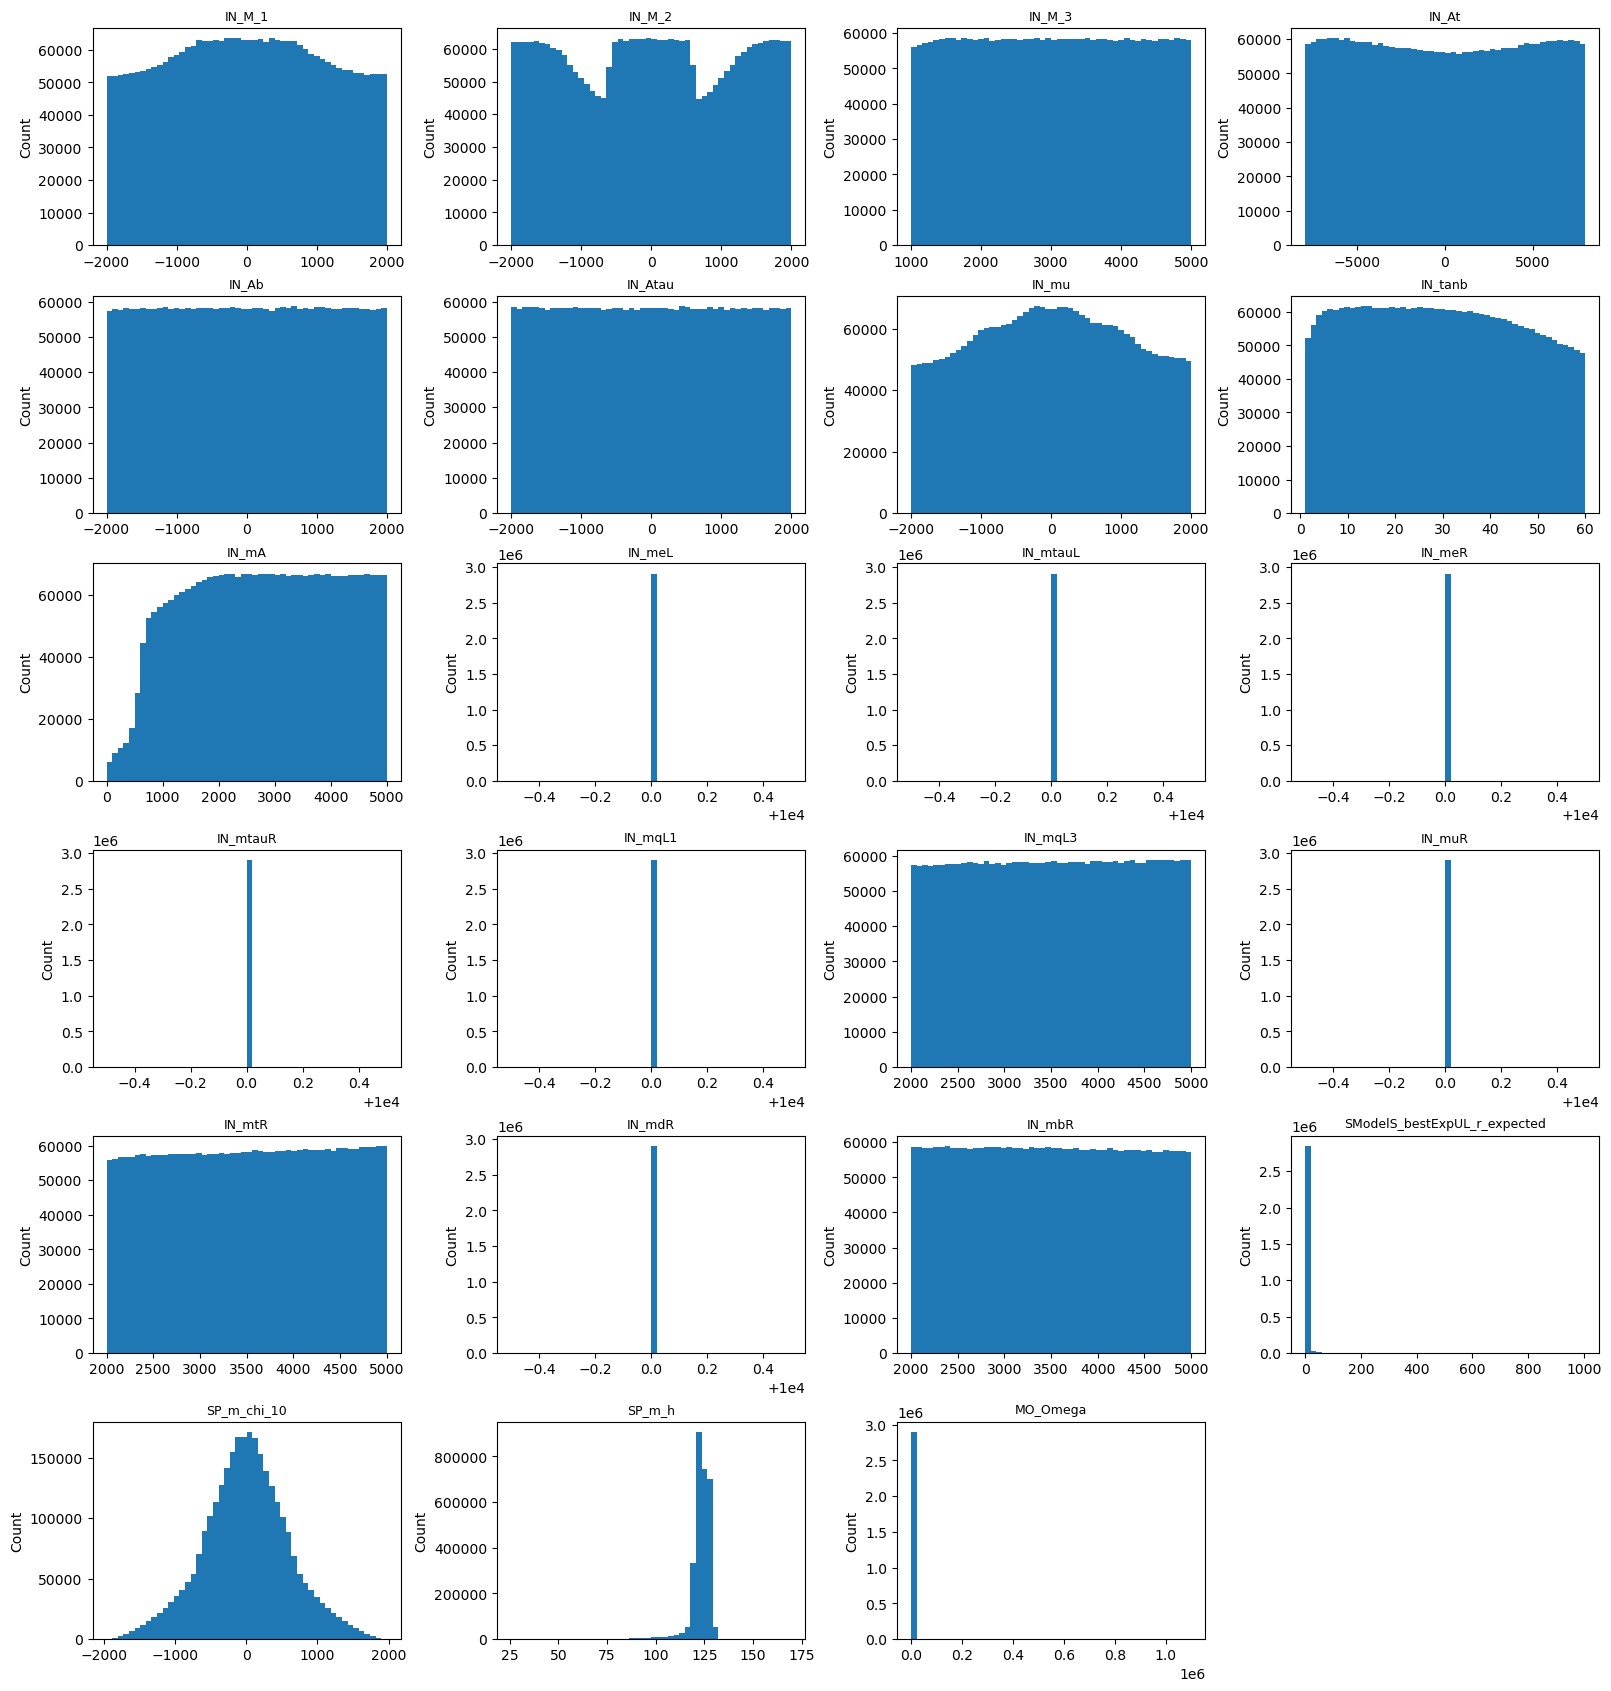

In [13]:
param_names = list(parameters)
ncols = 4
nrows = (len(param_names) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4 * ncols, 2.8 * nrows),
    squeeze=False,
    constrained_layout=True,
)

for ax, name in zip(axes.flat, param_names):
    values = np.asarray(parameters[name]).ravel()
    values = values[np.isfinite(values)]
    ax.hist(values, bins=50)
    ax.set_title(name, fontsize=9)
    ax.set_ylabel("Count")

for ax in axes.flat[len(param_names):]:
    ax.set_visible(False)

plt.show()